# Tandem lift – loss of load: coupled ship/load simulation

Python implementation of the simulation method of **Hatecke (2016), *Dynamics of Loss of Load during Tandem Lifts*** (TUHH dissertation, Ch. 2–4):

* a crane ship and the lifted load are two rigid bodies connected by the **one remaining crane rope** (rigid, massless rod) → **11 DOF** in minimal coordinates (ship 6, rope 2, load 3) – eqs. (2.2)–(2.16);
* equations of motion via Jacobian + **D'Alembert's principle** (2.44)–(2.48);
* **failure of the second rope**: switch to 12 independent DOF and state transformation (2.49)–(2.69);
* applied forces: gravity, **non‑linear hydrostatics**, **radiation forces as a state‑space system** (no convolution), **viscous roll damping**;
* analyses of Ch. 4: delay time `t_d`, crane configuration (load yaw `e0`), quasi‑static criterion adjustment, direct assessment of required GM.

The test case is the model‑test ship of Ch. 3 (Tables 3.1–3.4, full scale).

### What is taken from the thesis and what is *my* simplification
| Item | In the thesis | In this notebook |
|---|---|---|
| Multibody kinematics / kinetics, rope failure, state transformation | as in Ch. 2 | **same**; $\dot J\dot y$ by a directional finite difference instead of eq. (2.29); load Euler sequence changed to $R_z R_x R_y$ (gimbal lock at 90° load swing with the thesis' $R_zR_yR_x$) |
| Hydrostatics | 3‑DOF look‑up table from hull offsets | lever‑arm curve **digitised from Fig. 3.4** (sine‑series fit) for roll; linear heave (`Awp`) and pitch (`GM_L`) – assumed values |
| Radiation forces | BEM (NEWDRIFT) + own MIMO time‑domain identification with passivity enforcement | **placeholder** diagonal `A∞`, `B(ω)` (assumed), retardation function `K(τ)` (2.78) fitted by a stable state‑space model; stability + passivity are *checked* |
| Viscous roll damping | Ikeda simplified method | linear equivalent damping ratio, calibrated on the first roll peak of Fig. 3.14 |
| After 2nd rope failure | 12 DOF | ship (6 DOF) only – the free load is decoupled from the ship (eq. 2.63) |

So the numbers are *consistent with* – not a replacement of – the validated thesis results. Plug in your own BEM data (`A_inf`, `B(ω)`) to go further.

## 1  Data (thesis Tables 3.1–3.4, Fig. 3.4) and derived quantities

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares


from scipy.linalg import expm
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.grid':True})

Conventions (thesis 2.1): inertial frame **E** on the calm water surface, ship frame **S** in the ship COG (x forward, y to port, z up), rope frame **R** at the crane tip, load frame **L** in the load COG. Roll `φ` is positive about +x, i.e. **heel to starboard**; the load hangs on the port side.

Derived: ship mass without load, `KG` of the ship alone, transverse/longitudinal COG offsets such that the *loaded* system floats upright and untrimmed (ballast, Tab. 3.3), and the sine‑series fit of the hull lever arm `GZ_hull(φ)` digitised from the "after loss of load" curve of Fig. 3.4.

In [2]:
g=9.81; rho=1000.0
L_pp=149.38; m_tot=23300e3; m_L=1200e3; m_S=m_tot-m_L
KG_tot=11.61; GM0=4.49; k_xx=12.43; draught=9.0
tip_fwd=np.array([56.02,31.22,51.05]); tip_aft=np.array([68.66,31.22,51.05])
l_rope=14.89; ex=6.32; ez=2.92; i_L=np.array([1.50,4.05,4.24])
x_B=L_pp/2; Awp=3300.0; GM_L=170.0; k_yy=k_zz=0.25*L_pp
phi_deg=np.arange(0,75,5.)
h2_dig=np.array([-1.732,-1.154,-0.686,-0.34,0.037,0.411,0.664,0.803,0.87,0.908,0.912,0.855,0.747,0.599,0.428])
phi_f=np.deg2rad(43.46)
com_L=np.array([0.5*(tip_fwd[0]+tip_aft[0]),tip_fwd[1],tip_fwd[2]-l_rope-ez])
# ship COG from static equilibrium
KG_S=(KG_tot*m_tot-m_L*tip_fwd[2])/m_S
e_G=m_L*tip_fwd[1]/m_S
x_G=x_B+m_L*(x_B-com_L[0])/m_S
r_G=np.array([x_G,-e_G,KG_S])
I_S=m_S*np.diag([k_xx**2,k_yy**2,k_zz**2]); I_L=m_L*np.diag(i_L**2)
# GZ hull curve: sine series fit
GZh_dig=h2_dig+1.732*np.cos(np.deg2rad(phi_deg))
_K=np.arange(1,6)
_A=np.sin(np.outer(np.deg2rad(phi_deg),_K))
a_gz=np.linalg.lstsq(_A,GZh_dig,rcond=None)[0]
def GZ_hull(phi,dGM=0.0):
    return np.sin(np.outer(np.atleast_1d(phi),_K))@a_gz+dGM*np.sin(phi)


print(f"m_S = {m_S/1e3:.0f} t,  KG_ship = {KG_S:.2f} m,  COG offset y = {-e_G:.3f} m, x_G = {x_G:.2f} m from AP")
print("load COG (x,y,z from AP/CL/BL):", com_L.round(2))

m_S = 22100 t,  KG_ship = 9.47 m,  COG offset y = -1.695 m, x_G = 75.36 m from AP
load COG (x,y,z from AP/CL/BL): [62.34 31.22 33.24]


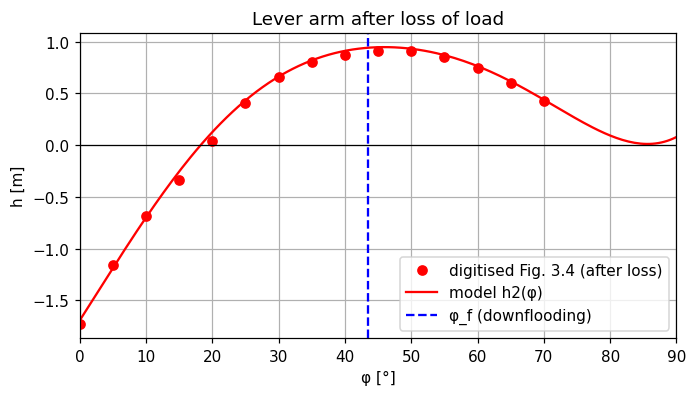

new static heel φ2 = 18.2°,  A1 = 0.256 m·rad,  A2 = 0.273 m·rad,  A2/A1 = 1.06  (loading condition was built for 1:1)


In [3]:
phi=np.deg2rad(np.linspace(-20,90,221))
h2=lambda p: GZ_hull(p)[0]-e_G*np.cos(p)                      # lever arm after loss of load (model)
fig,ax=plt.subplots(figsize=(7,3.6))
ax.plot(phi_deg,h2_dig,'ro',label='digitised Fig. 3.4 (after loss)')
pp=np.deg2rad(np.linspace(0,90,200)); ax.plot(np.rad2deg(pp),[h2(p) for p in pp],'r-',label='model h2(φ)')
ax.axhline(0,c='k',lw=.8); ax.axvline(np.rad2deg(phi_f),c='b',ls='--',label='φ_f (downflooding)')
ax.set(xlabel='φ [°]',ylabel='h [m]',xlim=(0,90),title='Lever arm after loss of load'); ax.legend(); plt.show()
from scipy.optimize import brentq
phi2=brentq(h2,0.1,1.0); 
A1=np.trapezoid(-np.array([h2(p) for p in np.linspace(0,phi2,400)]),np.linspace(0,phi2,400))
A2=np.trapezoid(np.array([h2(p) for p in np.linspace(phi2,phi_f,400)]),np.linspace(phi2,phi_f,400))
print(f"new static heel φ2 = {np.rad2deg(phi2):.1f}°,  A1 = {A1:.3f} m·rad,  A2 = {A2:.3f} m·rad,  A2/A1 = {A2/A1:.2f}  (loading condition was built for 1:1)")

## 2  Kinematics, Jacobian (eqs. 2.2–2.26)

Generalised coordinates $y=[\xi_S,\alpha_S,\alpha_R,\alpha_H]^T$ (11 DOF). The Jacobian maps $\dot y$ to $[\dot r_{ES},\omega_{ES},\dot r_{EL},\omega_{EL}]$. It is verified against finite differences of the load position and orientation.

In [4]:
def Rx(a):
    c,s=np.cos(a),np.sin(a); return np.array([[1,0,0],[0,c,-s],[0,s,c]])
def Ry(a):
    c,s=np.cos(a),np.sin(a); return np.array([[c,0,s],[0,1,0],[-s,0,c]])
def Rz(a):
    c,s=np.cos(a),np.sin(a); return np.array([[c,-s,0],[s,c,0],[0,0,1]])
def hat(v): return np.array([[0,-v[2],v[1]],[v[2],0,-v[0]],[-v[1],v[0],0]])
def P_zyx(th,psi):
    return np.array([[np.cos(th)*np.cos(psi),-np.sin(psi),0],[np.cos(th)*np.sin(psi),np.cos(psi),0],[-np.sin(th),0,1]])
def eulzyx(R):
    return np.array([np.arctan2(R[2,1],R[2,2]),-np.arcsin(np.clip(R[2,0],-1,1)),np.arctan2(R[1,0],R[0,0])])

class Config:
    def __init__(s,e0=np.pi,tip_z_fixed=True):
        s.e0=e0
        # remaining eye in load frame (+ex,0,+ez); yawed by e0 -> crane tip of remaining rope
        off=Rz(e0)@np.array([ex,0,ez])
        s.tip=com_L+off+np.array([0,0,l_rope])
        s.rSR_S=s.tip-r_G
        s.rHL_L=-np.array([ex,0,ez])
        s.y0=np.zeros(11); s.y0[10]=e0   # [xi(3),phi,th,psi,alpha,beta,gamma,delta,e]
        s.y0[0:3]=[0,0,KG_S-draught]  # E-frame: x,y arbitrary, z of COG above waterline

def kin(y,cfg):
    phi,th,psi=y[3:6]; al,be=y[6:8]; ga,de,ep=y[8:11]
    RES=Rz(psi)@Ry(th)@Rx(phi); RSR=Ry(be)@Rx(al); RRL=Rz(ep)@Rx(ga)@Ry(de)
    RER=RES@RSR
    r_SR=RES@cfg.rSR_S; r_RH=RER@np.array([0,0,-l_rope]); r_HL=RER@RRL@cfg.rHL_L
    return RES,RSR,RRL,RER,r_SR,r_RH,r_HL

def J11(y,cfg):
    RES,RSR,RRL,RER,r_SR,r_RH,r_HL=kin(y,cfg)
    be=y[7]; ga,de,ep=y[8:11]
    PES=P_zyx(y[4],y[5])
    PSR=RES@np.array([[np.cos(be),0],[0,1],[-np.sin(be),0]])
    c1=np.array([np.cos(ep),np.sin(ep),0])
    c2=np.array([-np.sin(ep)*np.cos(ga),np.cos(ep)*np.cos(ga),np.sin(ga)])
    PRH=RER@np.column_stack([c1,c2,[0,0,1]])
    r_RL=r_RH+r_HL; r_SL=r_SR+r_RL
    J=np.zeros((12,11))
    J[0:3,0:3]=np.eye(3); J[3:6,3:6]=PES
    J[6:9,0:3]=np.eye(3); J[6:9,3:6]=-hat(r_SL)@PES; J[6:9,6:8]=-hat(r_RL)@PSR; J[6:9,8:11]=-hat(r_HL)@PRH
    J[9:12,3:6]=PES; J[9:12,6:8]=PSR; J[9:12,8:11]=PRH
    return J
def Jdot_yd(Jfun,y,yd,cfg):
    eps=1e-6/max(1.0,np.abs(yd).max())
    return (Jfun(y+eps*yd,cfg)-Jfun(y-eps*yd,cfg))@yd/(2*eps)

def r_load(y,cfg):
    RES,RSR,RRL,RER,r_SR,r_RH,r_HL=kin(y,cfg); return y[0:3]+r_SR+r_RH+r_HL
def R_load(y,cfg):
    RES,RSR,RRL,RER,*_=kin(y,cfg); return RER@RRL

In [5]:
cfg=Config(np.pi)            # e0 = 180°: model-test configuration (aft hook released first, forward crane remains)
rng=np.random.default_rng(0); y=cfg.y0+0.2*rng.standard_normal(11); yd=rng.standard_normal(11)
v=J11(y,cfg)@yd; eps=1e-6
dr=(r_load(y+eps*yd,cfg)-r_load(y-eps*yd,cfg))/(2*eps)
Rd=(R_load(y+eps*yd,cfg)-R_load(y-eps*yd,cfg))/(2*eps); W=Rd@R_load(y,cfg).T
print("max error load velocity   :",np.abs(dr-v[6:9]).max())
print("max error load ang. vel.  :",np.abs(np.array([W[2,1],W[0,2],W[1,0]])-v[9:12]).max())
print("remaining crane tip (x,y,z) =",cfg.tip.round(2))

max error load velocity   : 3.917054458568714e-09
max error load ang. vel.  : 1.7918433403707468e-10
remaining crane tip (x,y,z) = [56.02 31.22 51.05]


## 3  Radiation forces as a state‑space system (Sect. 2.5)

Cummins' equation (2.76) with the convolution $\int K(\tau)\dot\xi(t-\tau)d\tau$ is replaced by $\dot x=Ax+B\dot\xi,\ \mu=Cx$ (2.80). The retardation function $K(\tau)=\frac2\pi\int_0^\infty[B(\omega)-B_\infty]\cos\omega\tau\,d\omega$ (2.78) is fitted with damped sinusoids (variable projection) and realised as a real block‑diagonal state‑space model (3 oscillators → order 6 per DOF).  
Requirements (2.5.1): **stability** (all eigenvalues of `A` in the left half plane) and **passivity** ($\Re\,\hat H(i\omega)\ge0$, eq. 2.81–2.83) – both are checked below.

> `A_inf` and the shape of `B(ω)` are **placeholders**. Replace them with BEM output to reproduce a specific ship.

In [6]:
def B_shape(w,Bpk,wp):
    x=w/wp; return Bpk*x**2*np.exp(1-x**2)
def retardation(Bpk,wp,tau):
    w=np.linspace(0,6*max(wp,0.3)+3,6000)
    Bw=B_shape(w,Bpk,wp)
    return np.array([2/np.pi*np.trapezoid(Bw*np.cos(w*t),w) for t in tau])
def fit_ss(tau,K,npairs=3):
    def lin(p):
        a=np.exp(p[:npairs]); b=p[npairs:]
        cols=[]
        for ai,bi in zip(a,b):
            cols+= [np.exp(-ai*tau)*np.cos(bi*tau),np.exp(-ai*tau)*np.sin(bi*tau)]
        return np.column_stack(cols)
    def res(p):
        M=lin(p); c=np.linalg.lstsq(M,K,rcond=None)[0]; return M@c-K
    best=None
    for trial in range(8):
        rng=np.random.default_rng(trial)
        p0=np.r_[np.log(rng.uniform(0.1,0.6,npairs)),rng.uniform(0.2,1.6,npairs)]
        r=least_squares(res,p0)
        if best is None or r.cost<best.cost: best=r
    p=best.x; M=lin(p); c=np.linalg.lstsq(M,K,rcond=None)[0]
    n=2*npairs; A=np.zeros((n,n)); B=np.zeros(n); C=np.zeros(n)
    for i in range(npairs):
        a=np.exp(p[i]); b=p[npairs+i]
        A[2*i:2*i+2,2*i:2*i+2]=[[-a,b],[-b,-a]]; B[2*i]=1; C[2*i]=c[2*i]; C[2*i+1]=-c[2*i+1]
    return A,B,C
def Bhat(A,B,C,w):
    n=len(B); return np.array([ (C@np.linalg.solve(1j*wi*np.eye(n)-A,B)).real for wi in w])

# 6-DOF diagonal hydrodynamic data (placeholders: replace by BEM results)
w_phi=np.sqrt(g*m_tot*GM0/(m_S*k_xx**2*1.15))
A_inf=np.array([0.05*m_S,0.9*m_S,1.1*m_S,0.15*m_S*k_xx**2,1.0*m_S*k_yy**2,0.8*m_S*k_zz**2])
def build_radiation(zeta_rad=0.04,npairs=3,verbose=False):
    C33=rho*g*Awp; C44=m_tot*g*GM0; C55=m_tot*g*GM_L
    Mdof=m_S*np.array([1.05,1.9,2.1,0,0,0]); 
    wp=np.array([0.3,0.4,0.85,0.55,0.8,0.4])
    crit=lambda C,M:2*np.sqrt(C*M)
    Bpk=np.array([0.05*(m_S*1.05)*0.3, 0.08*(m_S*1.9)*0.4, 0.2*crit(C33,m_S*2.1),
                  zeta_rad*crit(C44,m_S*k_xx**2*1.15),0.2*crit(C55,m_S*k_yy**2*2.0),0.05*(A_inf[5]+m_S*k_zz**2)*0.4])
    tau=np.arange(0,120,0.25); blocks=[]; fits=[]
    for i in range(6):
        K=retardation(Bpk[i],wp[i],tau); A,B,C=fit_ss(tau,K,npairs); blocks.append((A,B,C)); fits.append((Bpk[i],wp[i]))
    n=2*npairs
    Aall=np.zeros((6*n,6*n)); Ball=np.zeros((6*n,6)); Call=np.zeros((6,6*n))
    for i,(A,B,C) in enumerate(blocks):
        Aall[i*n:(i+1)*n,i*n:(i+1)*n]=A; Ball[i*n:(i+1)*n,i]=B; Call[i,i*n:(i+1)*n]=C
    return Aall,Ball,Call,blocks,fits

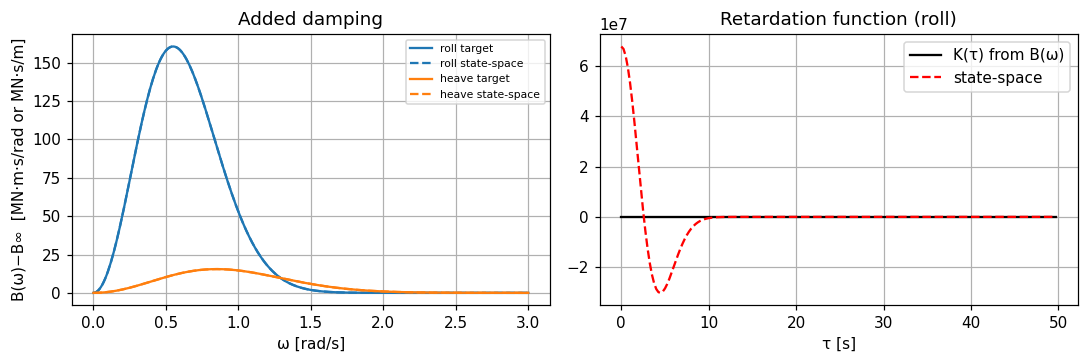

surge : max Re(eig A) =  -0.366   min B̆(ω)/max B̆ = -3.0e-05  (passive if ≥ 0 within fit tolerance)
sway  : max Re(eig A) =  -0.488   min B̆(ω)/max B̆ = -3.1e-05  (passive if ≥ 0 within fit tolerance)
heave : max Re(eig A) =  -1.045   min B̆(ω)/max B̆ = 3.2e-05  (passive if ≥ 0 within fit tolerance)
roll  : max Re(eig A) =  -0.671   min B̆(ω)/max B̆ = -1.1e-05  (passive if ≥ 0 within fit tolerance)
pitch : max Re(eig A) =  -0.982   min B̆(ω)/max B̆ = 1.8e-05  (passive if ≥ 0 within fit tolerance)
yaw   : max Re(eig A) =  -0.488   min B̆(ω)/max B̆ = -3.1e-05  (passive if ≥ 0 within fit tolerance)


In [7]:
Aall,Ball,Call,blocks,fits=build_radiation()
w=np.linspace(0,3,300); labels=['surge','sway','heave','roll','pitch','yaw']
fig,axs=plt.subplots(1,2,figsize=(10,3.4))
for i,c in zip([3,2],['C0','C1']):
    A,B,C=blocks[i]; tgt=B_shape(w,*fits[i]); got=Bhat(A,B,C,w)
    axs[0].plot(w,tgt/1e6,c+'-',label=labels[i]+' target'); axs[0].plot(w,got/1e6,c+'--',label=labels[i]+' state-space')
axs[0].set(xlabel='ω [rad/s]',ylabel='B(ω)−B∞  [MN·m·s/rad or MN·s/m]',title='Added damping'); axs[0].legend(fontsize=7)
tau=np.arange(0,120,.25); K=retardation(*fits[3],tau)
A,B,C=blocks[3]; Kss=[C@expm(A*t)@B for t in tau[:200]]
axs[1].plot(tau[:200],K[:200]/1e6,'k-',label='K(τ) from B(ω)'); axs[1].plot(tau[:200],Kss,'r--',label='state-space'); axs[1].set(xlabel='τ [s]',title='Retardation function (roll)'); axs[1].legend()
plt.tight_layout(); plt.show()
for i,(A,B,C) in enumerate(blocks):
    print(f"{labels[i]:6s}: max Re(eig A) = {np.linalg.eigvals(A).real.max():7.3f}   min B̆(ω)/max B̆ = {Bhat(A,B,C,w).min()/Bhat(A,B,C,w).max():.1e}  (passive if ≥ 0 within fit tolerance)")

## 4  Equations of motion (Sect. 2.2–2.3)

Phase 1 (rope still connected, 11 DOF):  
$J^TM_tJ\,\ddot y = J^T(q_{t,a}-M_t\dot J\dot y-k_t)$, eq. (2.44).  
Applied forces $q_{t,a}$ (2.70): gravity, hydrostatic force/moment, radiation wrench $-\mu$, viscous roll moment $n_v=-d_{44}\,p$ (2.115). Added mass `A∞` is added to the ship mass matrix.

Hydrostatic wrench (replacing the 3‑DOF look‑up table): $F_B=\rho g\nabla_0-\rho g A_{wp}\zeta$, roll moment $-F_B\,[GZ_{hull}(\varphi)-e_G\cos\varphi]$, pitch moment $-F_B[(x_B-x_G)\cos\vartheta+GM_L\sin\vartheta]$.

Phase 2 (second rope failed): the load is a free body and no longer influences the ship (2.63); the ship (6 DOF) is integrated with the same forces and the radiation states carried over. The load state at the instant of failure follows from eqs. (2.64)–(2.69) (`load_state_transform`).

In [8]:
class Hydro: pass
def make_hydro(zeta_rad=0.04,zeta_visc=0.11,dGM=0.0,npairs=3):
    h=Hydro(); h.A,h.B,h.C,*_=build_radiation(zeta_rad,npairs)
    h.d44=2*zeta_visc*w_phi*(m_S*k_xx**2+A_inf[3]); h.dGM=dGM; h.n=h.A.shape[0]
    return h

def ship_mats(RES):
    Mtr=RES@np.diag(m_S+A_inf[:3])@RES.T
    Irot=RES@(I_S+np.diag(A_inf[3:]))@RES.T
    return Mtr,Irot
def ship_forces(yS,ydS,x,h,z0):
    phi,th,psi=yS[3:6]; RES=Rz(psi)@Ry(th)@Rx(phi)
    wE=P_zyx(th,psi)@ydS[3:6]
    nu=np.r_[RES.T@ydS[0:3],RES.T@wE]
    mu=h.C@x
    FB=m_tot*g-rho*g*Awp*(yS[2]-z0)
    Mx=-FB*(GZ_hull(phi,h.dGM)[0]-e_G*np.cos(phi))
    My=-FB*((x_B-x_G)*np.cos(th)+GM_L*np.sin(th))
    f=np.array([0,0,FB-m_S*g])+RES@(-mu[0:3])
    n=Rz(psi)@np.array([Mx,My,0])+RES@(-mu[3:6]+np.array([-h.d44*nu[3],0,0]))
    return f,n,nu,RES

def rhs1(t,s,cfg,h,z0):
    y=s[:11]; yd=s[11:22]; x=s[22:]
    f,n,nu,RES=ship_forces(y[:6],yd[:6],x,h,z0)
    J=J11(y,cfg); Jd=Jdot_yd(J11,y,yd,cfg)
    Mtr,Irot=ship_mats(RES)
    RELf=kin(y,cfg); RL=RELf[3]@RELf[2]
    IL=RL@I_L@RL.T
    Mt=np.zeros((12,12)); Mt[0:3,0:3]=Mtr; Mt[3:6,3:6]=Irot; Mt[6:9,6:9]=m_L*np.eye(3); Mt[9:12,9:12]=IL
    v=J@yd; wS=v[3:6]; wL=v[9:12]
    k=np.r_[0,0,0,np.cross(wS,Irot@wS),0,0,0,np.cross(wL,IL@wL)]
    qa=np.r_[f,n,[0,0,-m_L*g],[0,0,0]]
    ydd=np.linalg.solve(J.T@Mt@J,J.T@(qa-Mt@Jd-k))
    return np.r_[yd,ydd,h.A@x+h.B@nu]

def constraint_force(s,cfg,h,z0):
    y=s[:11]; yd=s[11:22]; x=s[22:]
    d=rhs1(0,s,cfg,h,z0); ydd=d[11:22]
    J=J11(y,cfg); Jd=Jdot_yd(J11,y,yd,cfg)
    a=J@ydd+Jd
    RELf=kin(y,cfg); RL=RELf[3]@RELf[2]; IL=RL@I_L@RL.T
    wL=(J@yd)[9:12]
    fL=m_L*a[6:9]-np.array([0,0,-m_L*g])
    return fL

def rhs2(t,s,h,z0):
    y=s[:6]; yd=s[6:12]; x=s[12:]
    f,n,nu,RES=ship_forces(y,yd,x,h,z0)
    Mtr,Irot=ship_mats(RES)
    P=P_zyx(y[4],y[5]); e=1e-6
    Pd=((P_zyx(y[4]+e*yd[4],y[5]+e*yd[5])-P_zyx(y[4]-e*yd[4],y[5]-e*yd[5]))/(2*e))
    w=P@yd[3:6]
    acc_t=np.linalg.solve(Mtr,f)
    wd=np.linalg.solve(Irot,n-np.cross(w,Irot@w))
    ang=np.linalg.solve(P,wd-Pd@yd[3:6])
    return np.r_[yd,acc_t,ang,h.A@x+h.B@nu]

def simulate(td,cfg,h,t_end_after=25.0,rtol=1e-7,atol=1e-9,dense1=None):
    z0=cfg.y0[2]
    if dense1 is None:
        dense1=run_phase1(cfg,h,td+1.0,rtol,atol)
    s=dense1.sol(td)
    yS=np.r_[s[0:6],s[11:17]]
    s2=np.r_[yS,s[22:]]
    sol2=solve_ivp(rhs2,[td,td+t_end_after],s2,args=(h,z0),method='DOP853',rtol=rtol,atol=atol,max_step=0.5,dense_output=True)
    return dense1,sol2,s
def run_phase1(cfg,h,t_end,rtol=1e-7,atol=1e-9):
    s0=np.r_[cfg.y0,np.zeros(11),np.zeros(h.n)]
    return solve_ivp(rhs1,[0,t_end],s0,args=(cfg,h,cfg.y0[2]),method='DOP853',rtol=rtol,atol=atol,max_step=0.25,dense_output=True)

def load_state_transform(s,cfg):
    y=s[:11]; yd=s[11:22]; J=J11(y,cfg); v=J@yd
    xiL=r_load(y,cfg); xiLd=v[6:9]; RL=R_load(y,cfg); aL=eulzyx(RL)
    return xiL,xiLd,aL,np.linalg.solve(P_zyx(aL[1],aL[2]),v[9:12])

## 5  Validation against the thesis' model tests (full scale)

Reference values below were **read by eye from the thesis figures** (E4 = the thesis' simulation): Fig. 3.13 (rope force peaks at ≈1.12, 2.88, 4.65, 6.05 s with ≈4200, 4600, 4400, 6500 t), Fig. 3.12/3.14 (first coupled roll peak ≈1.2°) and Fig. 3.14 (roll after `t_d` = 6.6 s: max ≈31.5° at ≈12.6 s, new equilibrium ≈19.5°). The viscous damping ratio was tuned once on the 31.5° peak.

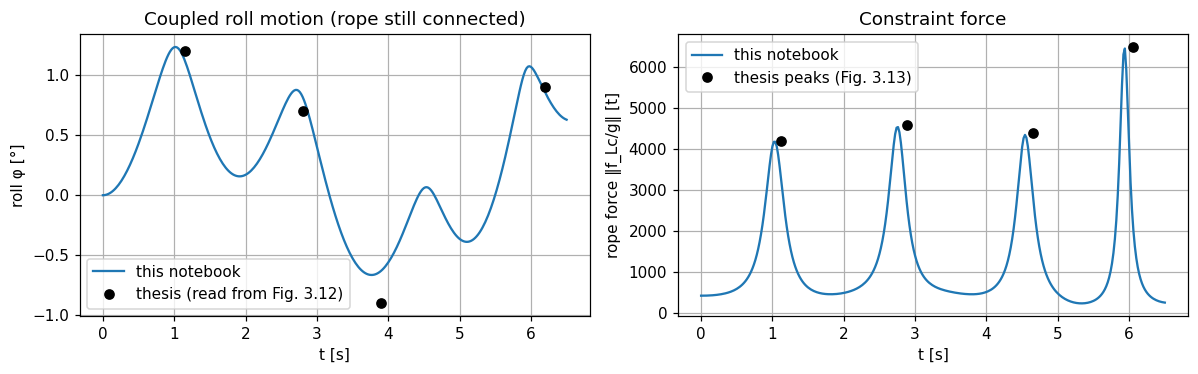

force peaks  t [s]: [1.02 2.76 4.54 5.94]   F [t]: [4186. 4546. 4354. 6463.]    min force [t]: 242.0


In [9]:
from scipy.signal import find_peaks
cfg=Config(np.pi); hyd=make_hydro()
sol1=run_phase1(cfg,hyd,31.0)
t=np.arange(0,6.51,0.02); S=sol1.sol(t)
F=np.array([np.linalg.norm(constraint_force(sol1.sol(tt),cfg,hyd,cfg.y0[2]))/g/1000 for tt in t])
pk,_=find_peaks(F,height=1500)
ref_t=np.array([1.12,2.88,4.65,6.05]); ref_F=np.array([4200,4600,4400,6500])
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
ax[0].plot(t,np.rad2deg(S[3]),label='this notebook'); ax[0].plot([1.15,2.8,3.9,6.2],[1.2,0.7,-0.9,0.9],'ko',label='thesis (read from Fig. 3.12)')
ax[0].set(xlabel='t [s]',ylabel='roll φ [°]',title='Coupled roll motion (rope still connected)'); ax[0].legend()
ax[1].plot(t,F,label='this notebook'); ax[1].plot(ref_t,ref_F,'ko',label='thesis peaks (Fig. 3.13)')
ax[1].set(xlabel='t [s]',ylabel='rope force ‖f_Lc/g‖ [t]',title='Constraint force'); ax[1].legend(); plt.tight_layout(); plt.show()
print("force peaks  t [s]:",t[pk].round(2),"  F [t]:",F[pk].round(0),"   min force [t]:",F.min().round(0))

## 6  Loss of the second rope, `t_d` = 6.6 s (Fig. 3.14)

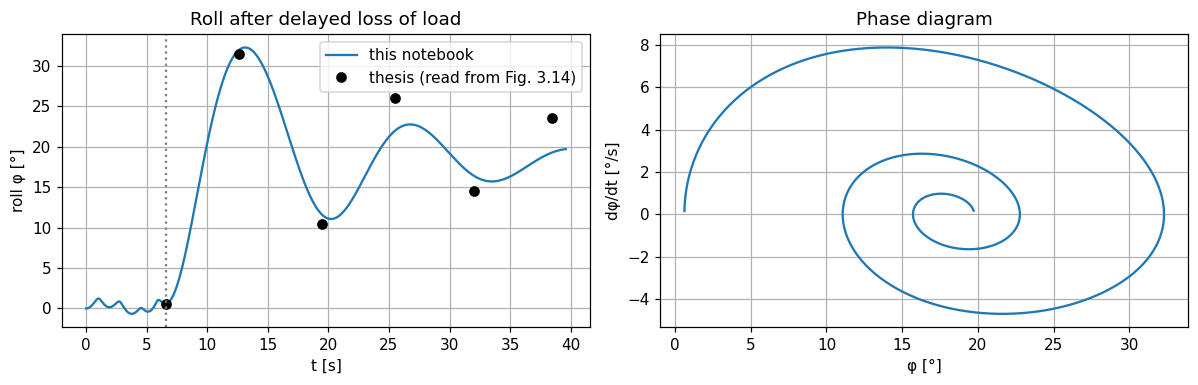

φ(t_d) = 0.62°,  φ_max = 32.3° at t = 13.1 s (6.5 s after failure),  final heel ≈ 18.4°
free load at failure (eq. 2.64-2.69):  COG height above waterline = 22.2 m,  vertical speed = -0.03 m/s


In [10]:
td=6.6
d1,sol2,s_td=simulate(td,cfg,hyd,t_end_after=33.0,dense1=sol1)
t1=np.linspace(0,td,200); t2=np.linspace(td,td+33,1500)
ph1=np.rad2deg(d1.sol(t1)[3]); ph2=np.rad2deg(sol2.sol(t2)[3])
ref=np.array([[6.6,0.5],[12.6,31.5],[19.5,10.5],[25.5,26],[32,14.5],[38.5,23.5]])
fig,ax=plt.subplots(1,2,figsize=(11,3.6))
ax[0].plot(t1,ph1,'C0'); ax[0].plot(t2,ph2,'C0',label='this notebook'); ax[0].plot(*ref.T,'ko',label='thesis (read from Fig. 3.14)')
ax[0].axvline(td,c='gray',ls=':'); ax[0].set(xlabel='t [s]',ylabel='roll φ [°]',title='Roll after delayed loss of load'); ax[0].legend()
ax[1].plot(np.rad2deg(sol2.sol(t2)[3]),np.rad2deg(sol2.sol(t2)[9]),'C0'); ax[1].set(xlabel='φ [°]',ylabel='dφ/dt [°/s]',title='Phase diagram'); plt.tight_layout(); plt.show()
print(f"φ(t_d) = {np.rad2deg(s_td[3]):.2f}°,  φ_max = {ph2.max():.1f}° at t = {t2[ph2.argmax()]:.1f} s ({t2[ph2.argmax()]-td:.1f} s after failure),  final heel ≈ {ph2[-200:].mean():.1f}°")
xiL,xiLd,aL,aLd=load_state_transform(s_td,cfg)
print("free load at failure (eq. 2.64-2.69):  COG height above waterline =",xiL[2].round(1),"m,  vertical speed =",xiLd[2].round(2),"m/s")

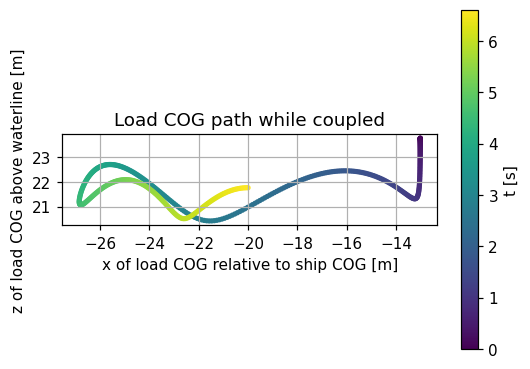

In [11]:
# load motion relative to the ship in the vertical x-z plane (coupled phase)
tt=np.linspace(0,td,400); ys=d1.sol(tt)
pts=np.array([r_load(ys[:11,k],cfg)-ys[0:3,k] for k in range(tt.size)])
fig,ax=plt.subplots(figsize=(5.5,4)); sc=ax.scatter(pts[:,0],pts[:,2],c=tt,s=6)
plt.colorbar(sc,label='t [s]'); ax.set_aspect('equal'); ax.set(xlabel='x of load COG relative to ship COG [m]',ylabel='z of load COG above waterline [m]',title='Load COG path while coupled'); plt.show()

## 7  Dependency on the delay time (Sect. 4.2, Fig. 4.2)

For the same lift, the second rope is released at `t_d` = 0 … 30 s (0.5 s steps). The maximum roll angle is plotted against the roll angle at the moment of the second failure.

61 runs in 10 s


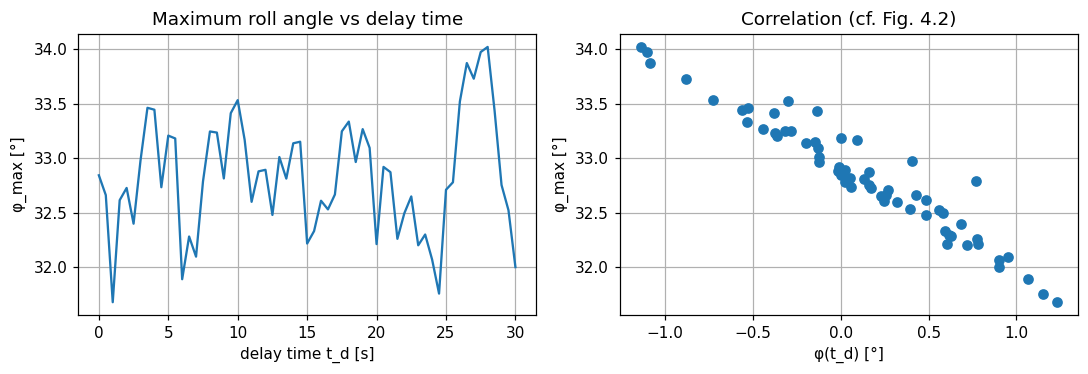

correlation coefficient φ(t_d) vs φ_max: -0.96   worst case over t_d: φ_max = 34.0 ° at t_d = 28.0 s


In [12]:
import time
def sweep_td(cfg,hyd,tds,dense1=None,tail=30.0):
    if dense1 is None: dense1=run_phase1(cfg,hyd,max(tds)+1.0)
    out=[]
    for td_ in tds:
        d1,s2,s=simulate(td_,cfg,hyd,t_end_after=tail,dense1=dense1)
        tt_=np.linspace(td_,td_+tail,600); out.append((np.rad2deg(s[3]),np.rad2deg(s2.sol(tt_)[3]).max()))
    return np.array(out)
tds=np.arange(0,30.01,0.5); t0=time.time()
R=sweep_td(cfg,hyd,tds,sol1)
print(f"{len(tds)} runs in {time.time()-t0:.0f} s")
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].plot(tds,R[:,1]); ax[0].set(xlabel='delay time t_d [s]',ylabel='φ_max [°]',title='Maximum roll angle vs delay time')
ax[1].plot(R[:,0],R[:,1],'o'); ax[1].set(xlabel='φ(t_d) [°]',ylabel='φ_max [°]',title='Correlation (cf. Fig. 4.2)')
plt.tight_layout(); plt.show()
print("correlation coefficient φ(t_d) vs φ_max:",np.corrcoef(R[:,0],R[:,1])[0,1].round(2),"  worst case over t_d: φ_max =",R[:,1].max().round(1),"° at t_d =",tds[R[:,1].argmax()],"s")

## 8  Lifting configuration (Sect. 4.3, Figs. 4.3–4.4)

With crane‑tip height, load COG and suspended length fixed, the only free parameter is the load yaw angle `e0` (the transverse spacing of the crane tips). `e0` ∈ [0°, 180°]: the inboard crane fails first (outboard rope remains); `e0` ∈ [180°, 360°]: the outboard crane fails first. For each `e0` the loss of load is simulated for `t_d` = 0…30 s and the highest roll angle is taken.

372 runs in 79 s


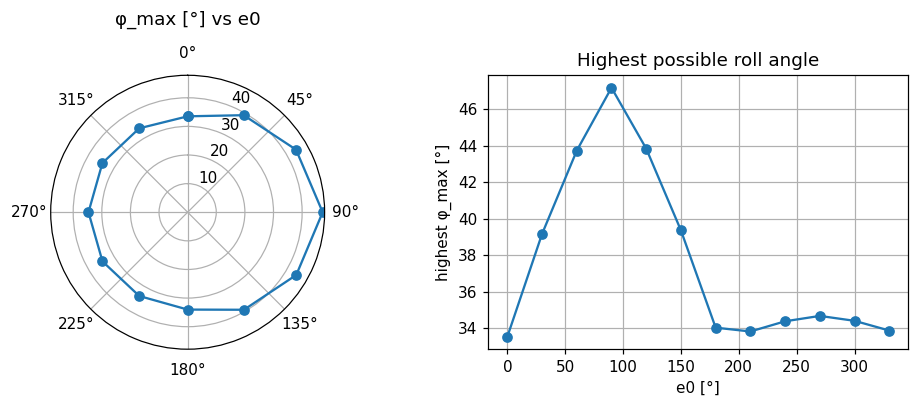

 e0 [°]  tip y of remaining crane [m]  φ_max [°]  φ(t_d) at worst [°]  worst t_d [s]
      0                         31.22       33.5                 -0.7            4.0
     30                         34.38       39.2                 -5.9            8.0
     60                         36.69       43.7                -10.4            8.0
     90                         37.54       47.2                -13.5            9.0
    120                         36.69       43.8                -10.6            9.0
    150                         34.38       39.4                 -6.0            9.0
    180                         31.22       34.0                 -1.1           28.0
    210                         28.06       33.8                 -0.3            4.0
    240                         25.75       34.4                 -0.1            4.0
    270                         24.90       34.7                 -0.0            4.0
    300                         25.75       34.4                 

In [13]:
e0s=np.arange(0,360,30); res=[]; t0=time.time()
tds2=np.arange(0,30.01,1.0)
for e0 in e0s:
    c=Config(np.deg2rad(e0)); d1_=run_phase1(c,hyd,31.0)
    Rr=sweep_td(c,hyd,tds2,d1_,tail=25.0); res.append((Rr[:,1].max(),Rr[Rr[:,1].argmax(),0],tds2[Rr[:,1].argmax()],c.tip[1]))
res=np.array(res); print(f"{len(e0s)*len(tds2)} runs in {time.time()-t0:.0f} s")
fig=plt.figure(figsize=(9,3.8)); ax=fig.add_subplot(121,projection='polar')
th=np.deg2rad(np.r_[e0s,360]); ax.plot(th,np.r_[res[:,0],res[0,0]],'o-'); ax.set_theta_zero_location('N'); ax.set_theta_direction(-1); ax.set_title('φ_max [°] vs e0',pad=14)
ax2=fig.add_subplot(122); ax2.plot(e0s,res[:,0],'o-'); ax2.set(xlabel='e0 [°]',ylabel='highest φ_max [°]',title='Highest possible roll angle'); plt.tight_layout(); plt.show()
import pandas as pd
print(pd.DataFrame({'e0 [°]':e0s,'tip y of remaining crane [m]':res[:,3].round(2),'φ_max [°]':res[:,0].round(1),'φ(t_d) at worst [°]':res[:,1].round(1),'worst t_d [s]':res[:,2]}).to_string(index=False))

## 9  Quasi‑static adjustment of the area‑ratio criterion (Sect. 4.4)

If the unexcited ship oscillates about the new heel `φc` (static heel with the full load on the remaining tip) starting from `φ1`, the most dangerous roll angle at which the second crane can fail is the extremum of that oscillation, `φx = 2φc − φ1` (cf. eqs. 4.1–4.2). Replacing `φ1` by `φx` in the area ratio `A2/A1` (Fig. 1.5) accounts for the worst failure order and timing. Below, the criterion is evaluated for the test lift and for the two extreme crane configurations. The dynamic simulation above is the reference.

In [14]:
def static_heel(y_tip):
    # equilibrium of ship (23300 t displacement) with the full load hanging in the crane tip at transverse position y_tip
    z_t=tip_fwd[2]-KG_S
    def M(p):
        arm=(y_tip+e_G)*np.cos(p)-z_t*np.sin(p)
        return -m_tot*g*(GZ_hull(p)[0]-e_G*np.cos(p))-m_L*g*arm
    return brentq(M,-0.6,0.6)
def area_ratio(phi1):
    p2=brentq(h2,0.1,1.0); a=np.linspace(phi1,p2,500); b=np.linspace(p2,phi_f,500)
    A1=np.trapezoid(-np.array([h2(p) for p in a]),a); A2=np.trapezoid([h2(p) for p in b],b); return A1,A2
phi1=static_heel(tip_fwd[1]); print(f"initial heel with the load in both tips: {np.rad2deg(phi1):.2f}°")
rows=[]
for name,yt in [('test lift (no transverse offset)',tip_fwd[1]),('outboard crane remains (e0=90°)',tip_fwd[1]+ex),('inboard crane remains (e0=270°)',tip_fwd[1]-ex)]:
    phic=static_heel(yt); phix=2*phic-phi1; phiw=min(phi1,phix)      # worst extreme of the oscillation (towards the load side)
    A1,A2=area_ratio(phi1); A1w,A2w=area_ratio(phiw)
    rows.append((name,np.rad2deg(phic),np.rad2deg(phiw),A2/A1,A2w/A1w))
print(pd.DataFrame(rows,columns=['configuration','φc [°]','worst φ at failure [°]','A2/A1 (φ1)','A2/A1 (adjusted)']).round(2).to_string(index=False))
print("\nAn energy balance without dissipation lets the roll reach φ_f =",np.rad2deg(phi_f).round(1),"° when A2/A1 ≈ 1; the simulation of the test lift gives at most",R[:,1].max().round(1),"° -> the lever-arm criterion is conservative (thesis Sect. 4.5.1). The adjusted ratio drops well below 1 for the outboard case, in line with its much higher simulated φ_max.")

initial heel with the load in both tips: 0.00°
                   configuration  φc [°]  worst φ at failure [°]  A2/A1 (φ1)  A2/A1 (adjusted)
test lift (no transverse offset)    0.00                    0.00        1.06              1.06
 outboard crane remains (e0=90°)   -5.18                  -10.36        1.06              0.42
 inboard crane remains (e0=270°)    5.18                    0.00        1.06              1.06

An energy balance without dissipation lets the roll reach φ_f = 43.5 ° when A2/A1 ≈ 1; the simulation of the test lift gives at most 34.0 ° -> the lever-arm criterion is conservative (thesis Sect. 4.5.1). The adjusted ratio drops well below 1 for the outboard case, in line with its much higher simulated φ_max.


## 10  Direct assessment of the required stability (Sect. 4.5.2, Fig. 4.8)

The loading condition is kept, only `GM` is varied (change of `KG`: $GZ\to GZ+\Delta GM\sin\varphi$), and `t_d` = 6.6 s. Below a threshold `GM_cap` the ship capsizes (no flooding is modelled, as in the thesis footnote); the jump in `φ_max` identifies it. The vanishing‑stability angle of the digitised/extrapolated curve is used as capsize criterion.

17 runs in 47 s


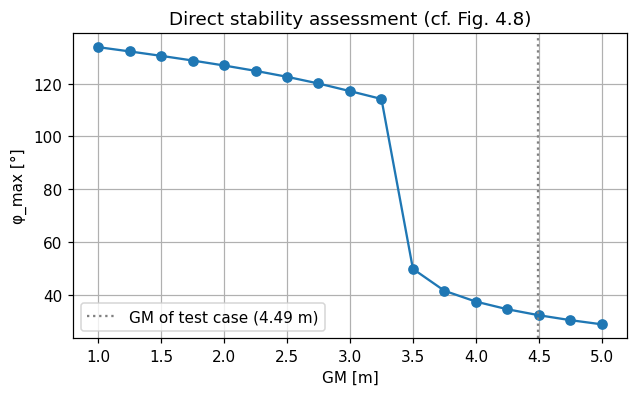

 GM [m]  φ_max [°]
   1.00      133.9
   1.25      132.2
   1.50      130.6
   1.75      128.8
   2.00      126.9
   2.25      124.9
   2.50      122.6
   2.75      120.1
   3.00      117.2
   3.25      114.2
   3.50       49.8
   3.75       41.5
   4.00       37.4
   4.25       34.5
   4.50       32.2
   4.75       30.3
   5.00       28.7

threshold stability GM_cap ≈ 3.50 m (first GM without capsize on this grid); the test case has GM = 4.49 m


In [15]:
gms=np.arange(1.0,5.01,0.25); out=[]; t0=time.time()
cfgT=Config(np.pi)
for gm in gms:
    hh=make_hydro(dGM=gm-GM0); d1_=run_phase1(cfgT,hh,7.6)
    _,s2,_=simulate(6.6,cfgT,hh,t_end_after=40.0,dense1=d1_)
    tt_=np.linspace(6.6,46.6,1200); out.append(np.rad2deg(s2.sol(tt_)[3]).max())
out=np.array(out); print(f"{len(gms)} runs in {time.time()-t0:.0f} s")
fig,ax=plt.subplots(figsize=(6.5,3.6)); ax.plot(gms,np.minimum(out,250),'o-'); ax.axvline(GM0,c='gray',ls=':',label='GM of test case (4.49 m)')
ax.set(xlabel='GM [m]',ylabel='φ_max [°]',title='Direct stability assessment (cf. Fig. 4.8)'); ax.legend(); plt.show()
print(pd.DataFrame({'GM [m]':gms,'φ_max [°]':out.round(1)}).to_string(index=False))
safe=gms[out<90]; print(f"\nthreshold stability GM_cap ≈ {safe.min():.2f} m (first GM without capsize on this grid); the test case has GM = {GM0} m")

## Notes and next steps

* **Replace the placeholders** for ship‑specific results: `A_inf` (6×6 and non‑diagonal terms), `B(ω)` from your BEM code (Capytaine/WAMIT/NEWDRIFT) and a hull‑based hydrostatic table `(ζ, φ, ϑ) → (F, M)`. The identification routine `fit_ss` is single‑input/single‑output; for the full 6×6 coupled model the thesis' MIMO identification with passivity enforcement (Sect. 2.5.2–2.5.4) would be needed.
* Roll damping: implement Ikeda's simplified method (friction, eddy, lift, bilge keels; eq. 2.114) instead of the calibrated damping ratio – it makes later roll cycles more accurate (the linear damping here decays faster than the measurements after the first peak).
* Not modelled (as in the thesis): rope/crane elasticity, rope and crane damping, load–water impact, downflooding.
* Reference values from the thesis figures were read graphically and are approximate.